# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
import pandas as pd
from numpy import nan
from helper_pandas import *

import matplotlib.pyplot as plt
import seaborn as sns


from joblib import load

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_diasemana,...,Diagnostico_clasificacion,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,Sábado,...,NaN,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,Sábado,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,Viernes,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,Domingo,...,NaN,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,Lunes,...,NaN,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


### Código de color


1. <span style="background:#0504aa">---</span> Poblacion
2. <span style="background:#999999">---</span> S-D  <span style="background:#d9d9d9">---</span> S-D (DF)
3. <span style="background:#377eb8">---</span> Masculino  <span style="background:#80b1d3">---</span> Masculino (DF)
4. <span style="background:#984ea3">---</span> Femenino  <span style="background:#bebada">---</span> Femenino (DF)
5. <span style="background:#4daf4a">---</span> Conocido
6. <span style="background:#ff7f00">---</span> Desconocido
7. <span style="background:#8dd3c7">---</span> Cadáver conocido
8. <span style="background:#fdb462">---</span> Cadáver desconocido
9. <span style="background:#f781bf">---</span> Recién nacido
10. <span style="background:#ffff33">---</span> Feto
11. <span style="background:#fb8072">---</span> Miembros
12. <span style="background:#a65628">---</span> Restos óseos 

* <span style="background:#e41a1c">---</span>
* <span style="background:#b3de69">---</span>
* <span style="background:#fccde5">---</span>
* <span style="background:#ffffb3">---</span> 

## Datos faltantes

### Datos faltantes por columna transcrita

In [2]:
col_trans = [c for c in df.columns if 'transcrito' in c]
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan = (df[col_trans]!='S-D')
df_notnan.sum()

Numero_progresivo_transcrito    27152
Nombre_completo_transcrito      96819
Fecha_transcrito                96611
Edad_transcrito                 40183
Diagnostico_transcrito          40966
Procedencia_transcrito          71064
Numero_acta_transcrito          71102
Expediente_SEMEFO_transcrito    96277
Foja_transcrito                 88845
dtype: int64

**Datos faltantes por año**

No todos los años se capturaron todas las variables.

* Edad y Diagnóstico solo fueron capturadas de 1974-1979
* Numero progresivo solo fue capturada de 1974 a 1978 y fue de manera irregular
* Procedencia y acta fueron capturadas de manera irregular de 1968 a 1963
* Foja no fue capturada en 1980

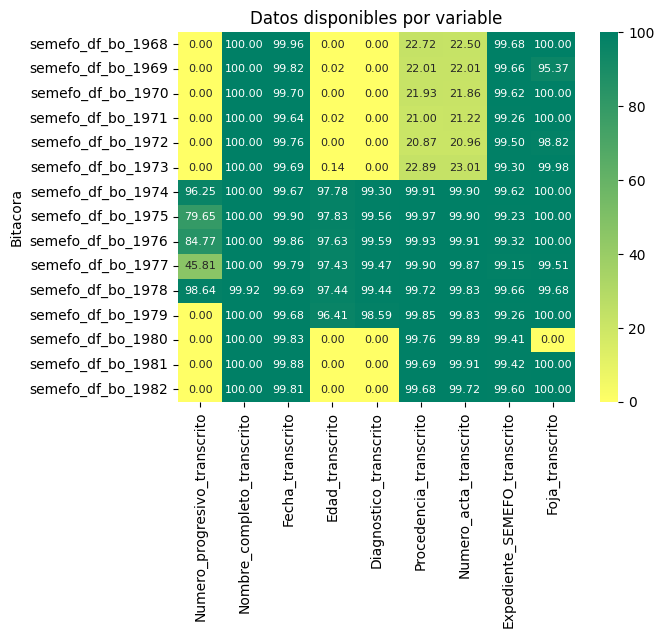

In [3]:
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan['Bitacora'] = df['Bitacora_ingresos']
df_notnan_anual = df_notnan.groupby('Bitacora').sum().divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap='summer_r', annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable")
plt.show()

Ignorando las variables que no fueron capturadas en el año

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:10: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  # Remove the CWD from sys.path while we load stuff.


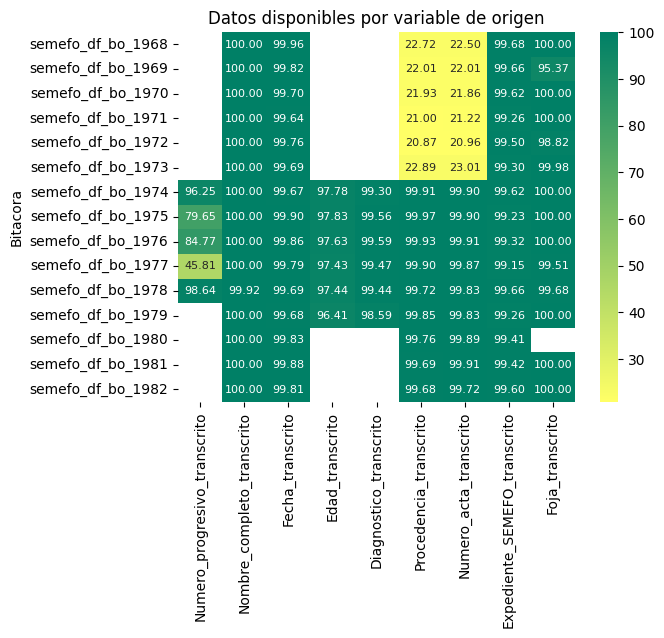

In [4]:
dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    df_notnan.loc[ df_notnan['Bitacora'].isin([f"semefo_df_bo_{a}" for a in años]), col] = nan
df_notnan

df_notnan_anual = df_notnan.groupby('Bitacora', dropna=False) \
                            .apply(lambda x: x.sum(skipna=False)) \
                            .divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap='summer_r', annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable de origen")
plt.show()

Correlación entre faltantes
* Existe una correlación alta  (0.996) entre la falta de procedencia y de acta.
* Existe una correlación debil entre la falta del nombre con la fecha (0.253) y el exp semefo (0.162)


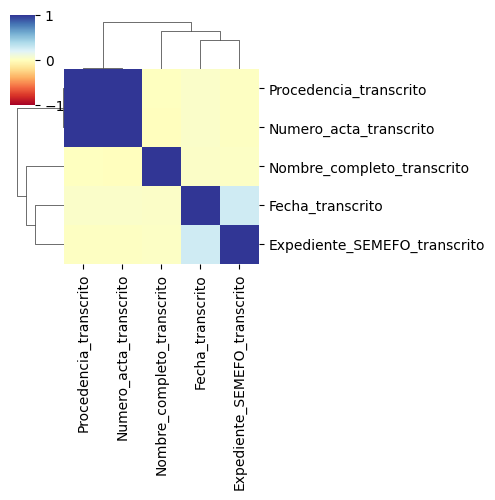

In [5]:
sns.clustermap(df_notnan.corr(), vmin=-1, vmax=1, cmap='RdYlBu', figsize=(5,5))
plt.show()

### Filas con más datos faltantes

* Casos donde hay número progresivo o foja pero ningun dato
* Casos donde solo hay nombre, muchas veces solo apellido
* Casos sin fecha pero con expediente

En general no parece haber un patrón, la cantidad de datos esta fuertemente asociada a que campos se capturaron ese año

In [6]:
df_notnan = (df[col_trans]!='S-D')
df_notnan['Bitacora'] = df['Bitacora_ingresos']

dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    años = [f"semefo_df_bo_{a}" for a in años]
    df_notnan.loc[ df_notnan['Bitacora'].isin(años), col] = nan

df_notnan_row = df_notnan.drop('Bitacora', axis=1).sum(axis=1).to_frame()
df_notnan_row.value_counts().sort_index()

1.0        6
2.0       58
3.0      459
4.0    25153
5.0     7900
6.0    22190
7.0      615
8.0    14044
9.0    26400
dtype: int64

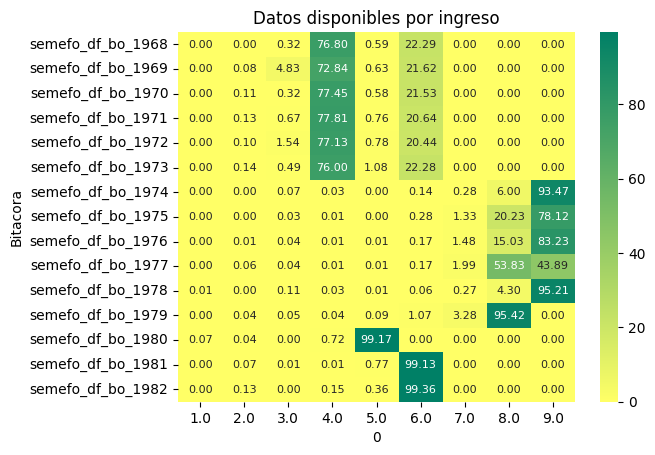

In [7]:
df_notnan_row['Bitacora'] = df['Bitacora_ingresos']
df_notnan_row_anual = df_notnan_row.pivot_table(columns=0, index='Bitacora', aggfunc='size')
df_notnan_row_anual = df_notnan_row_anual.divide(ingresos_anuales, axis=0)
sns.heatmap(df_notnan_row_anual*100, cmap='summer_r', annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por ingreso")
plt.show()

### Faltantes por tipo de restos

* De 1968 a 1973 faltan procedencia/acta para cadáveres conocidos
* De 1974 a 1979 faltan edades para miembros
* No todos los años hay restos oseos


Cadáver conocido


/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:7: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  import sys


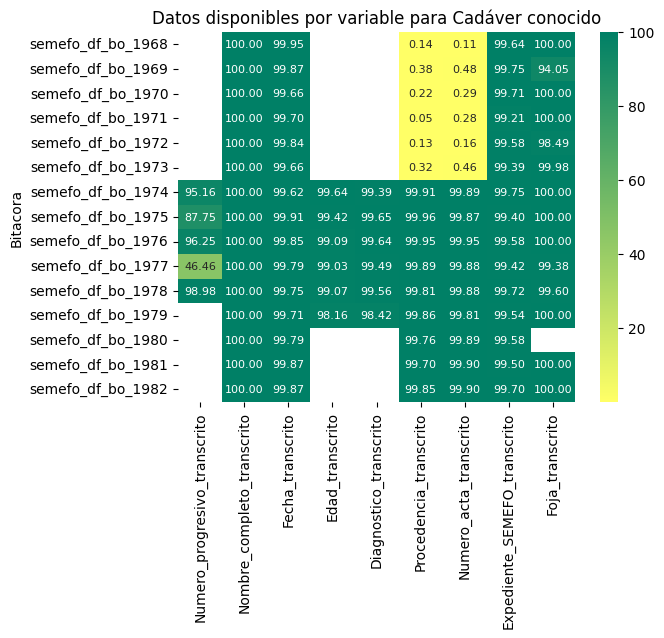

Cadáver desconocido


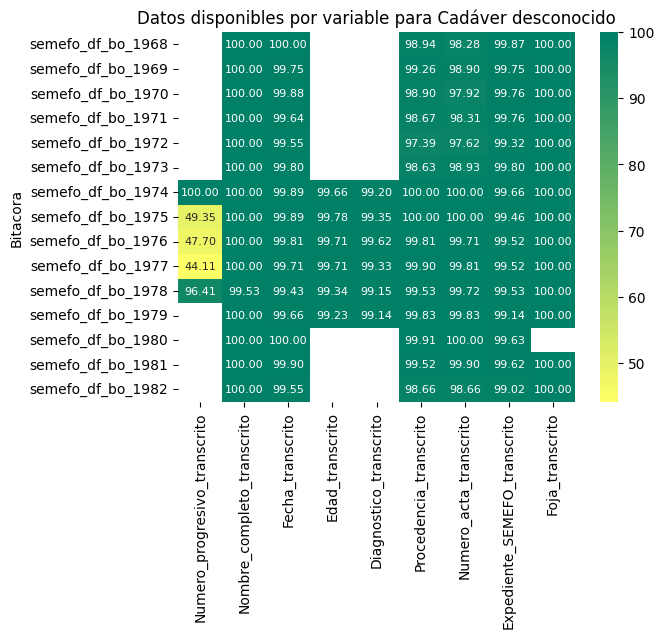

Miembros


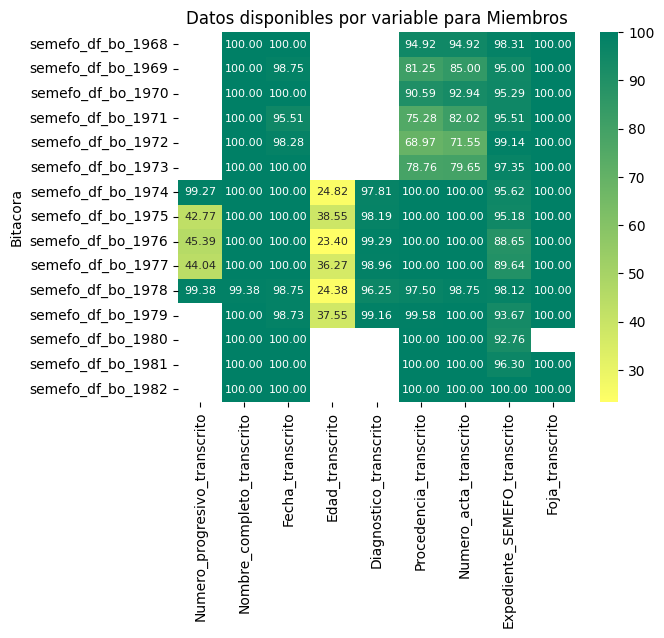

Feto


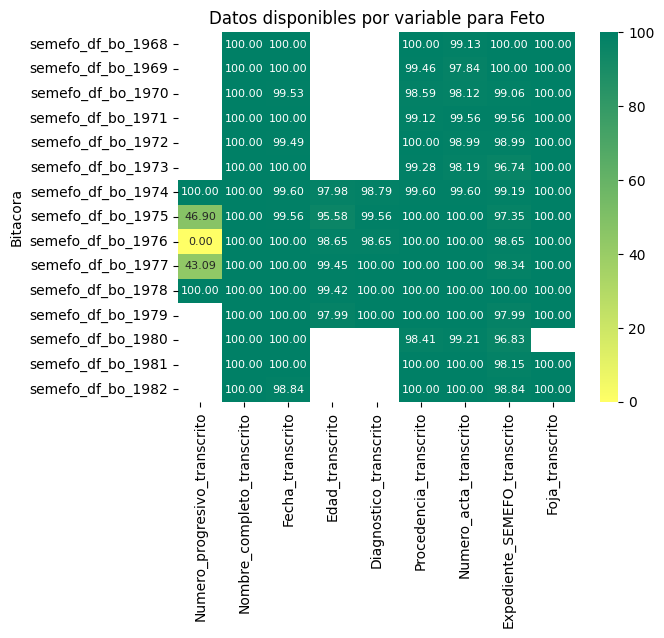

Restos óseos


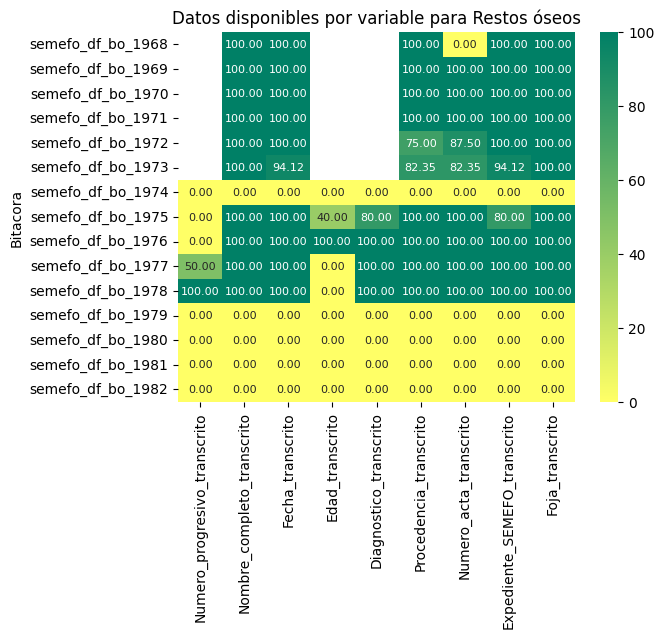

Recién nacido


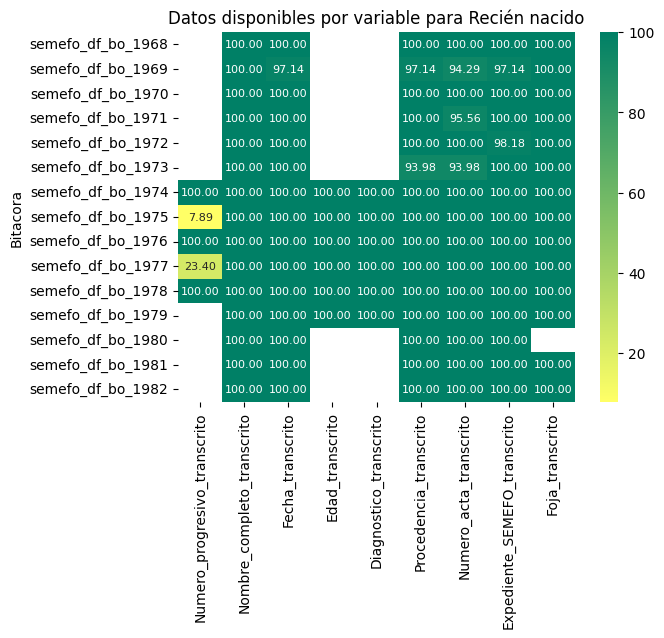

In [8]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    ingresos_anuales_tipo = df.loc[df['Tipo_restos']==tipo,'Bitacora_ingresos'].value_counts().sort_index()
    ingresos_anuales_tipo = ingresos_anuales_tipo.replace({0:1.0})
    data = df_notnan[df['Tipo_restos']==tipo]
    data_anual = data.groupby('Bitacora', dropna=False) \
                     .apply(lambda x: x.sum(skipna=False)) \
                     .div( ingresos_anuales_tipo, axis=0 )
    for col in data_anual.columns:
        data_anual[col] = pd.to_numeric(data_anual[col]*100)
    sns.heatmap(data_anual, cmap='summer_r', annot=True, fmt=".2f", annot_kws={"size": 8})
    plt.title(f"Datos disponibles por variable para {tipo}")
    plt.show()

## Resumen estadístico

**Tipo_restos**

In [9]:
categorical_to_freq_and_percentage(df['Tipo_restos']).to_frame().transpose()

,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos
0,76756 (79.273%),14479 (14.954%),2844 (2.937%),633 (0.654%),2065 (2.133%),48 (0.05%)


**Nombre**

In [10]:
string_summary(df['Nombre_completo_transcrito'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos
0,hernandez hernandez jesus 7 (0.007%),desconocido 12820 (13.24%),feto 2609 (2.695%),r. nacido 224 (0.231%),nombre confidencial 1880 (1.942%),osamenta 30 (0.031%)
1,lopez lopez mario 6 (0.006%),desconocida 1291 (1.333%),nombre confidencial 202 (0.209%),recien nacido 105 (0.108%),restos humanos 26 (0.027%),restos oseos 8 (0.008%)
2,garcia garcia juan 6 (0.006%),S-D 5 (0.005%),fetos 6 (0.006%),r. nacida 96 (0.099%),placenta 11 (0.011%),desconocido 3 (0.003%)
3,hernandez hernandez antonio 6 (0.006%),desconocido o guadalupe 4 (0.004%),desconocido (feto) 4 (0.004%),nombre confidencial 72 (0.074%),m.i. de: 8 (0.008%),huesos humanos 2 (0.002%)
4,lopez hernandez jose 5 (0.005%),"desconocido o pedro ""n"" 4 (0.004%)",feto (2 fetos) con una orden 2 (0.002%),recien nacida 61 (0.063%),miembro inferior 7 (0.007%),craneo 2 (0.002%)
5,Otro* 76726 (79.242%),Otro* 355 (0.367%),Otro* 21 (0.022%),Otro* 75 (0.077%),Otro* 133 (0.137%),Otro* 3 (0.003%)


''

**Conocido_desconocido**

In [11]:
categorical_summary(df['Conocido_desconocido'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos,Total
Conocido,76756 (79.273%),0 (0.0%),31 (0.032%),31 (0.032%),1795 (1.854%),0 (0.0%),78613 (81.191%)
Desconocido,0 (0.0%),14479 (14.954%),2813 (2.905%),602 (0.622%),270 (0.279%),48 (0.05%),18212 (18.809%)
S-D,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


**Sexo**

In [12]:
categorical_summary(df['Sexo'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos,Total
Femenino,17923 (18.511%),1580 (1.632%),462 (0.477%),251 (0.259%),384 (0.397%),1 (0.001%),20601 (21.277%)
Masculino,58337 (60.25%),12845 (13.266%),662 (0.684%),379 (0.391%),1511 (1.561%),7 (0.007%),73741 (76.159%)
S-D,496 (0.512%),54 (0.056%),1720 (1.776%),3 (0.003%),170 (0.176%),40 (0.041%),2483 (2.564%)


**Edad**

In [13]:
numeric_summary(df['Edad_estandar'],df['Tipo_restos'],percen_round=3)

,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos,All
count,32348,6094,1174,223,329,3,40171
mean,35.845,40.058,0,0,35.587,26,35.235
std,22.084,17.539,0,0,19.799,12.49,22.127
min,0,0,0,0,0,16,0
25%,20,28,0,0,20,19,20
50%,33,40,0,0,30,22,34
75%,52,50,0,0,48,31,50
max,108,90,0,0,91,40,108


**Diagnostico**

In [14]:
string_summary(df['Diagnostico_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=6,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos
0,Sin datos* 44782 (46.25%),Sin datos* 8499 (8.778%),Sin datos* 1687 (1.742%),Sin datos* 423 (0.437%),Sin datos* 1102 (1.138%),Sin datos* 40 (0.041%)
1,traumatismo multiple 6112 (6.312%),traumatismo multiple 1428 (1.475%),expulsion prematura del seno materno 543 (0.561%),asfixia neo natorum 75 (0.077%),amputacion quirurgica por traumatismo 608 (0.628%),indeterminado 3 (0.003%)
2,traumatismo craneo encefalico 5234 (5.406%),traumatismo craneo encefalico 782 (0.808%),asfixia neo natorum 461 (0.476%),bronconeumonia 32 (0.033%),gangrena 49 (0.051%),traumatismo craneo encefalico 2 (0.002%)
3,bronconeumonia 1272 (1.314%),bronconeumonia 699 (0.722%),indeterminado 36 (0.037%),asfixia por estrangulacion 16 (0.017%),traumatismo miembro 33 (0.034%),no copias 1 (0.001%)
4,congestion visceral generalizada 1153 (1.191%),bronconeumonia + cirrosis hepatica 427 (0.441%),falta cuidado post natales 18 (0.019%),traumatismo craneo encefalico 13 (0.013%),amputacion quirurgica por traumatismo + gangrena 30 (0.031%),traumatismo cervico 1 (0.001%)
5,traumatismo craneo torax 1033 (1.067%),congestion visceral generalizada 194 (0.2%),traumatismo craneo encefalico 14 (0.014%),bronconeumonia + enteritis 7 (0.007%),amputacion traumatica 29 (0.03%),herida arma fuego craneo 1 (0.001%)
6,Otro* 17170 (17.733%),Otro* 2450 (2.53%),Otro* 85 (0.088%),Otro* 67 (0.069%),Otro* 214 (0.221%),Otro* 0 (0.0%)


''

**Procedencia**

In [15]:
string_summary(df['Procedencia_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos
0,Sin datos* 25603 (26.443%),Coord Territorial 1 Venustiano Carranza (Col Merced) 1180 (1.219%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 310 (0.32%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 88 (0.091%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 425 (0.439%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 8 (0.008%)
1,Cruz Roja (Col Polanco) 3984 (4.115%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1170 (1.208%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 173 (0.179%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 41 (0.042%),Hospital Balbuena (Col Jardin Balbuena) 275 (0.284%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 7 (0.007%)
2,Hospital Balbuena (Col Jardin Balbuena) 3955 (4.085%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 1123 (1.16%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 137 (0.141%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 41 (0.042%),Hospital Xoco (Col General Anaya) 200 (0.207%),Sin datos* 6 (0.006%)
3,Coord Territorial 2 Coyoacan (Col Romero de Terreros) 3166 (3.27%),Hospital Balbuena (Col Jardin Balbuena) 1116 (1.153%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 134 (0.138%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 36 (0.037%),Cruz Roja (Col Polanco) 176 (0.182%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 5 (0.005%)
4,Hospital la Villa (Col Granjas Modernas) 2825 (2.918%),Cruz Roja (Col Polanco) 686 (0.708%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 129 (0.133%),Coord Territorial 6 Cuauhtemoc (Col Centro) 32 (0.033%),Hospital Ruben Leñero (Col Santo Tomas) 137 (0.141%),Coord Territorial 8 Cuauhtemoc (Col Obrera) 4 (0.004%)
5,Otro* 37223 (38.444%),Otro* 9204 (9.506%),Otro* 1961 (2.025%),Otro* 395 (0.408%),Otro* 852 (0.88%),Otro* 18 (0.019%)


''

top_strings

## Sexo y Edad

'Sexo', 
'Edad_transcrito', 
'Edad_estandar',
'Edad_grupo',

Cargando archivos de referencia del INEGI

Datos tomados de:
* Secretaría de Programación y Presupuesto. (1982). Defunciones registradas en la República Mexicana, 1933-1975. Coordinación General de los Servicios Nacionales de Estadística, Geografía e Informática. ISBN 968-809-593-1.
* Instituto Nacional de Estadística, Geografía e Informática. (1994). Defunciones en los Estados Unidos Mexicanos, 1976-1992. INEGI. ISBN 970-13-0098-X.

In [16]:
df_inegi_edad = pd.read_csv('data_raw/INEGI_defunciones_sexo_1966-1984.csv', index_col='Edad_grupo')
df_inegi_edad

,Sexo,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984
Edad_grupo,,,,,,,,,,,,,,,,,,,,
Total,Total,53820.0,56693.0,59872.0,62937.0,66158.0,64301.0,66804.0,55052.0,52767.0,50631.0,51284,47637,47741,48421,49848,48486,47715,48947,46777
Masculino,Masculino,28365.0,29981.0,31704.0,33265.0,35088.0,34279.0,35583.0,29211.0,28045.0,26854.0,27102,25289,25267,26073,26876,26210,25851,26505,24762
"[0.0, 0.083)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4748.0,4665.0,4212,4012,2889,3622,3694,3355,3259,3116,2606
"[0.0, 1.0)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8520.0,8221.0,7941,6942,5513,6240,6163,5617,5355,5254,4817
"[1.0, 2.0)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,527.0,533.0,616,411,358,368,282,290,289,268,241
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"[70.0, 75.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,5,2,1,4,5,4,3
"[75.0, 80.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,2,0,5,4,2,4
"[80.0, 85.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1,1,1,2,5,5,4


### Ingresos anuales por sexo

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:31: UserWarning: FixedFormatter should only be used together with FixedLocator


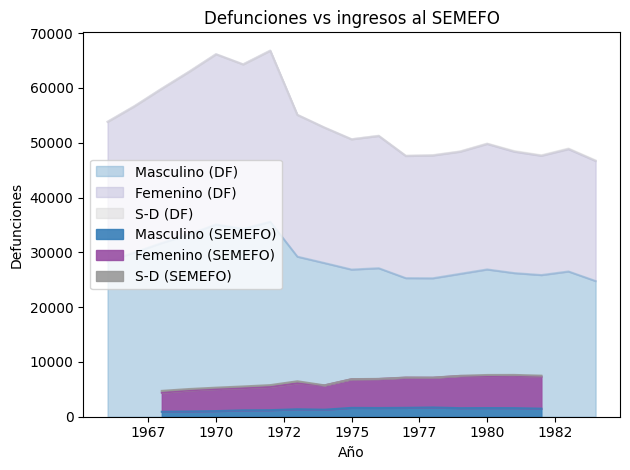

In [17]:
dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

df_año_sexo = df.pivot_table(index='Bitacora_ingresos', columns='Sexo', aggfunc='size')
df_año_sexo.index = [int(y.replace('semefo_df_bo_','')) for y in df_año_sexo.index]
df_año_sexo.columns = ['Masculino (SEMEFO)','Femenino (SEMEFO)','S-D (SEMEFO)',]
df_año_sexo

df_año_sexo_inegi = df_inegi_edad.loc[['Masculino','Femenino','S-D']].transpose().drop('Sexo')
df_año_sexo_inegi.index = [int(i) for i in df_año_sexo_inegi.index]
df_año_sexo_inegi.columns = ['Masculino (DF)','Femenino (DF)','S-D (DF)']
df_año_sexo_inegi

# Create the figure and axes object
fig, ax = plt.subplots()

# Plot the first area plot
df_año_sexo_inegi.plot.area(ax=ax, alpha=0.5, color=dic_colors)

# Plot the second area plot on the same axes
df_año_sexo.plot.area(ax=ax, alpha=0.9, color=dic_colors)

# Add labels and title
ax.set_xlabel('Año')
ax.set_ylabel('Defunciones')
ax.set_title('Defunciones vs ingresos al SEMEFO')

# Display the legend
ax.legend()
ax.legend(loc='center left')
ax.set_xticklabels([int(x) for x in ax.get_xticks()]) # Remove negative sign from tick labels
# Plotting
plt.tight_layout()
plt.show()

### Distribución de edad

Picos en edades terminadas en 0 o 5

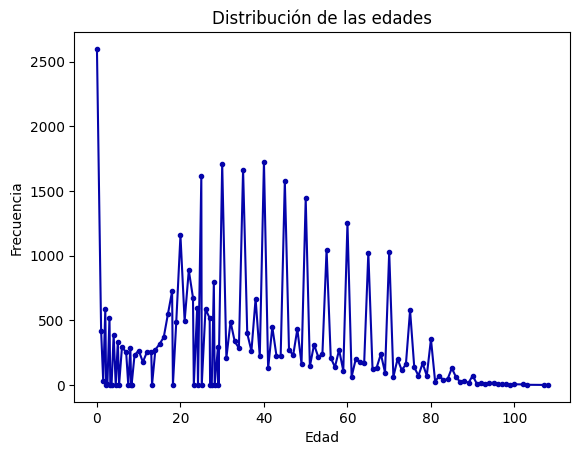

In [30]:
edad_freq = df['Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades",
               xlabel='Edad', ylabel='Frecuencia', color='#0504aa'
              )
plt.show()

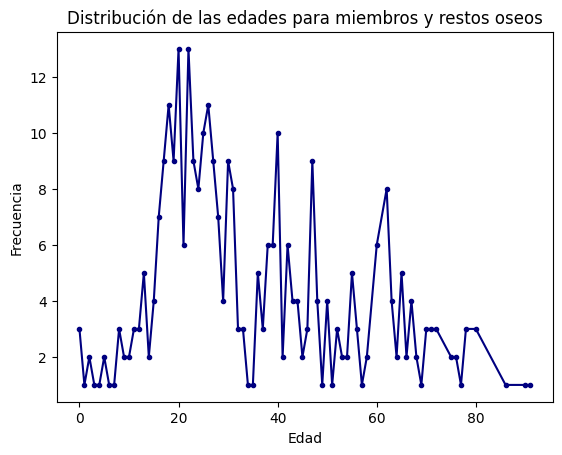

In [28]:
edad_freq = df.loc[df['Tipo_restos'].isin(['Miembros','Restos óseos']),'Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades para miembros y restos oseos",
               xlabel='Edad', ylabel='Frecuencia', color='navy'
              )
plt.show()

### Edad vs sexo

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:35: UserWarning: FixedFormatter should only be used together with FixedLocator


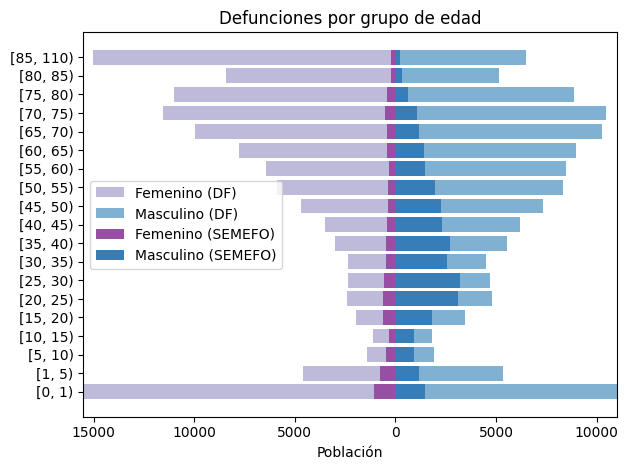

In [20]:
# Calcular frecuencia por grupo de edad y sexo
edad_sexo = df[~df['Tipo_restos'].isin(['Miembros','Restos óseos'])] \
                .pivot_table(index='Edad_grupo',columns='Sexo',values='Edad_estandar',aggfunc='count')
#display(edad_sexo)

años_edad = ['1974','1975','1976','1977','1978','1979']
index_edad = ['[0.0, 1.0)', '[1.0, 5.0)', '[5.0, 10.0)', '[10.0, 15.0)', '[15.0, 20.0)', '[20.0, 25.0)', '[25.0, 30.0)', 
              '[30.0, 35.0)', '[35.0, 40.0)', '[40.0, 45.0)', '[45.0, 50.0)', '[50.0, 55.0)', '[55.0, 60.0)', 
              '[60.0, 65.0)', '[65.0, 70.0)', '[70.0, 75.0)', '[75.0, 80.0)', '[80.0, 85.0)', '[85.0, 110.0)']
data = df_inegi_edad.loc[index_edad,['Sexo']+años_edad]
data['Freq']= data[años_edad].sum(axis=1)
data = data.reset_index().pivot(index='Edad_grupo', columns='Sexo', values='Freq').fillna(0)
data = data.loc[index_edad]
#display(data)

dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

# Set position for each age group
y = range(len(edad_sexo)) 
# Plotting
fig, ax = plt.subplots()
ax.barh(y, [-val for val in data['Femenino']], color='#bebada', label='Femenino (DF)') # Plot female bars (negative)
ax.barh(y, data['Masculino'], color='#80b1d3', label='Masculino (DF)') # Plot male bars (positive)
ax.barh(y, [-val for val in edad_sexo['Femenino']], color='#984ea3', label='Femenino (SEMEFO)') # Plot female bars (negative)
ax.barh(y, edad_sexo['Masculino'], color='#377eb8', label='Masculino (SEMEFO)') # Plot male bars (positive)
# Y-axis label and formatting
plt.xlim( -15500, 11000 )
ax.set_yticks(y) # Set age groups as y-ticks (on horizontal axis)
ax.set_yticklabels(edad_sexo.index)
# X-axis label and formatting
ax.set_xlabel('Población')
ax.set_title('Defunciones por grupo de edad')
ax.legend(loc='center left')
ax.set_xticklabels([abs(int(x)) for x in ax.get_xticks()]) # Remove negative sign from tick labels
# Plotting
plt.tight_layout()
plt.show()

## Fecha
'Fecha_transcrito', 
'Fecha_estandar', 
'Fecha_año', 
'Fecha_mes',
'Fecha_diasemana',

### Ingresos diarios/semanales

Tipo_restos,Cadáver conocido,Cadáver desconocido,Feto,Recién nacido,Miembros,Restos óseos
Fecha_año,,,,,,
1968.0,3638,754,229,34,59,2
1969.0,3929,814,185,34,79,4
1970.0,4112,816,212,53,84,5
1971.0,4317,827,226,45,85,3
1972.0,4501,879,197,55,114,8
1973.0,4705,1021,276,83,113,16
1974.0,4639,873,246,52,137,0
1975.0,5499,922,225,38,165,5
1976.0,5477,1042,222,8,142,1


<AxesSubplot:xlabel='Fecha_año'>

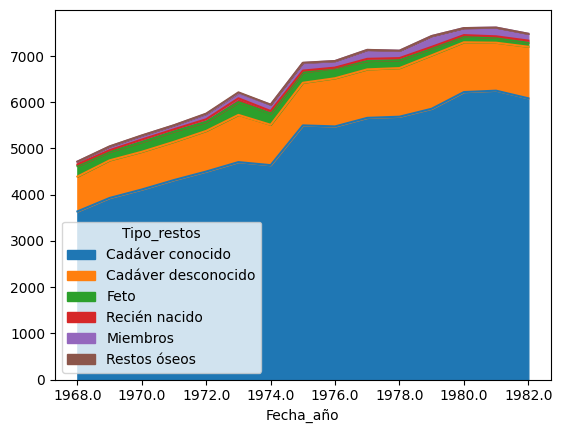

In [21]:
df_año_tipo = df.pivot_table(index='Fecha_año', columns='Tipo_restos', aggfunc='size')
display( df_año_tipo )
df_año_tipo.plot.area()

In [22]:
ing_diarios = df[[]]

### Periodicidad entre años, meses, dia semana

### Ingresos fuera de año

<AxesSubplot:xlabel='ID'>

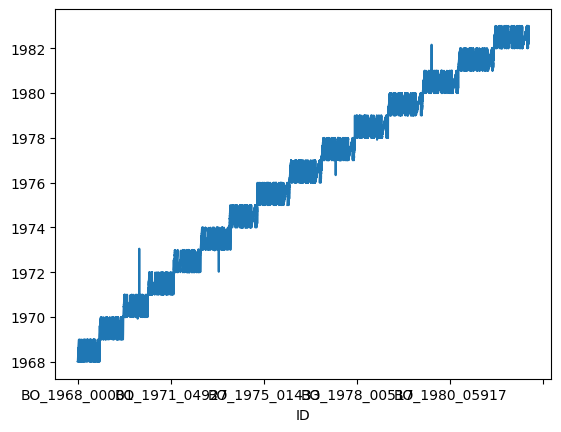

In [23]:
df['Fecha_estandar'].plot()

## Proceso administrativo
'Numero_progresivo_transcrito', 
'Numero_acta_transcrito', 
'Expediente_SEMEFO_transcrito',
'Bitacora_ingresos', 
'Foja_transcrito', 
'Observaciones'

## Nombre
'Nombre_completo_transcrito',
'Primer_apellido', 
'Segundo_apellido', 
'Nombres_propios',

## Diagnostico
'Diagnostico_transcrito', 
'Diagnostico_estandar',
'Diagnostico_extendido', 
'Diagnostico_clasificacion',

## Procedencia
'Procedencia_transcrito', 
'Procedencia_estandar',
'Procedencia_extendido', 
'Procedencia_alcaldia',
       
## Conocido_desconocido
'Conocido_desconocido',

tabla por grupo de edad y sexo de principales causas de muerte